# fisherNN v2 — gauge-aware Fisher-discriminant layers

**What changed from v1**
- **Stable solver.** Whitening by `eigh(S_W)` and both eigensolves in float64 on CPU (LAPACK), with
  β = 0.1 by default. β caps every generalized eigenvalue at 1/β, so the solve can't chase near-null
  S_W directions. This removes both the eigh crash and the seed-dependent 1-class collapse.
- **Gauge modes on re-solve:** `none`, `procrustes` (now in the *regularized* S_W metric the filters
  are normalized in), `signed_perm` (Hungarian matching — an exact symmetry of the [ReLU(z), ReLU(−z)]
  encoder), and `cluster` (signed-perm across eigenvalue clusters, Procrustes inside near-degenerate ones).
- **Drift measured in the data's geometry:** S_W-metric distance before/after signed-perm matching
  (how much of the change is pure gauge), principal angles in the S_T metric, and linear CKA between
  the old and new network's outputs on fixed test images.
- **Fixed bugs from the last cell** (`train_task` positional args) and one fixed `POOL` throughout.
- **Memory.** Ridge-readout statistics, solves and readout transport run in float64 on CPU
  (`STAT_DEV`); the GPU only extracts features. GPU memory is released between runs, and the peak is
  printed after each one.

**Hypotheses**
- **H0 (symmetry check).** A signed permutation of a layer's filters, plus the matching re-indexing of
  the next layer's input statistics, leaves the network *exactly* unchanged. A rotation in the
  S_W metric does not — it changes the function.
- **H1.** Most of L1's raw drift between tasks is gauge (signed permutations), not subspace change.
- **H2.** With signed-perm alignment, γ = 1 (fully additive statistics) becomes valid, and continuing to
  update the body no longer loses to freezing it.
- **H3.** β > 0 removes the seed-dependent collapse seen in v1 (1-class L3 = 0.416 vs 0.696).
- **H4.** The width gains survive a matched-width random-filter control.

Set `SMOKE = True` to run everything on tiny synthetic data (a few minutes on CPU) before a real run.

In [1]:
import math, copy, time, gc
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

try:                                    # same SSL fix as v1, harmless if certifi is missing
    import ssl, certifi
    ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
except ImportError:
    pass

SMOKE = False
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED = 0
BETA = 0.1                              # S_W += BETA * S_T; caps the Fisher ratio at 1/BETA
POOL = 4                                # one pooling size for every probe and readout
STAT_DEV = 'cpu'                        # where ridge-readout statistics live and are solved (float64).
                                        # The GPU only extracts features. Set to dev if you have >16 GB.
TRANSPORT_N = None                      # images used to fit the readout transport map (None = whole task)
TASKS = [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]

if SMOKE:
    WIDTHS, CNN_WIDTHS = (8, 16, 32), (16, 32, 64)
    FIT_N, PROBE_N, N_CKA, BP_EPOCHS = None, None, 300, 1
    WIDTH_GRID = [(8, 16, 32), (16, 32, 64)]
else:
    WIDTHS, CNN_WIDTHS = (32, 64, 128), (64, 128, 256)
    FIT_N   = 10000      # images for fitting FD bodies in exps 0-2 (v1: n=5000 == n=50000)
    PROBE_N = 20000      # training images for the ridge probe in exps 1-2 (None = all 50k)
    N_CKA   = 1000       # fixed test images for CKA / drift diagnostics
    BP_EPOCHS = 3        # backprop epochs per task in the CI baselines
    WIDTH_GRID = [(32, 64, 128), (64, 128, 256)]   # add (75, 256, 512) if memory allows

RUN = dict(symmetry=True, stability=True, width=True, ci=True, bp=True)
RESULTS = {}            # CI curves, filled by exps 3-4

## Data, augmentation, pooling

In [2]:
def load_cifar(root='./data'):
    import torchvision
    tr = torchvision.datasets.CIFAR10(root, train=True, download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    f = lambda d: torch.tensor(d.data).permute(0, 3, 1, 2).float() / 255
    Xtr, Xte = f(tr), f(te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, torch.tensor(tr.targets), (Xte - mean) / std, torch.tensor(te.targets)

def load_synthetic(n_tr=1500, n_te=500, seed=0):
    """10 classes of smooth colour templates + structured noise + random shifts. For code checks only."""
    g = torch.Generator().manual_seed(seed)
    T = F.interpolate(torch.randn(10, 3, 4, 4, generator=g), size=32, mode='bicubic', align_corners=False)
    def make(n):
        y = torch.randint(0, 10, (n,), generator=g)
        x = (T[y] * (0.5 + torch.rand(n, 1, 1, 1, generator=g))
             + 0.7 * F.interpolate(torch.randn(n, 3, 8, 8, generator=g), size=32, mode='bilinear',
                                   align_corners=False)
             + 0.3 * torch.randn(n, 3, 32, 32, generator=g))
        s = torch.randint(-3, 4, (n, 2), generator=g)
        x = torch.stack([torch.roll(x[i], tuple(s[i].tolist()), (1, 2)) for i in range(n)])
        return x, y
    Xtr, Ytr = make(n_tr); Xte, Yte = make(n_te)
    mean, std = Xtr.mean((0, 2, 3), keepdim=True), Xtr.std((0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, Ytr, (Xte - mean) / std, Yte

def augment(x):
    """v1 augmentation: photometric + a shared 1-px roll per call (two calls -> relative shift)."""
    B = x.shape[0]
    x = x * (1 + 0.4 * (torch.rand(B, 1, 1, 1, device=x.device) - 0.5))
    x = x + 0.3 * torch.randn(B, 3, 1, 1, device=x.device)
    x = x + 0.1 * torch.randn_like(x)
    dy, dx = torch.randint(-1, 2, (2,)).tolist()
    return torch.roll(x, (dy, dx), (2, 3))

pool = lambda h: F.adaptive_avg_pool2d(h, POOL).flatten(1)

Xtr, Ytr, Xte, Yte = load_synthetic() if SMOKE else load_cifar()
def subset(n, seed=SEED):
    if n is None or n >= len(Xtr): return Xtr, Ytr
    idx = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(seed))[:n]
    return Xtr[idx], Ytr[idx]
print(f'device {dev} | train {tuple(Xtr.shape)} | test {tuple(Xte.shape)} | smoke={SMOKE}')

Files already downloaded and verified
Files already downloaded and verified
device cuda | train (50000, 3, 32, 32) | test (10000, 3, 32, 32) | smoke=False


## Stable generalized eigensolver and gauge alignment

All filter matrices below are S_W-orthonormal (WᵀS_W W = I, with S_W the *regularized* matrix),
so `C = W_newᵀ S_W W_old` is a matrix of cosines in the S_W metric.

In [3]:
@torch.no_grad()
def gen_eig(ST, SW, k):
    """Top-k solutions of S_T w = λ S_W w. float64 on CPU; whitening via eigh(S_W), no explicit inverse."""
    ST, SW = ST.double().cpu(), SW.double().cpu()
    s, V = torch.linalg.eigh((SW + SW.T) / 2)
    s = s.clamp_min(s.max() * 1e-12)
    Linv = (V / s.sqrt()).T                     # Linv S_W Linvᵀ = I
    M = Linv @ ST @ Linv.T
    lam, U = torch.linalg.eigh((M + M.T) / 2)
    lam, U = lam.flip(0)[:k], U.flip(1)[:, :k]
    return lam, Linv.T @ U                      # Wᵀ S_W W = I

def eig_clusters(lam, tol):
    """Group consecutive eigenvalues whose relative gap is below tol (near-degenerate = genuine gauge)."""
    groups, cur = [], [0]
    for i in range(1, len(lam)):
        if (lam[i - 1] - lam[i]) <= tol * lam[i - 1].abs(): cur.append(i)
        else: groups.append(cur); cur = [i]
    groups.append(cur)
    return groups

@torch.no_grad()
def signed_perm(W, W_old, SW):
    """Best signed permutation matching columns of W to W_old. Returns (perm, signs) with
    aligned[:, perm[j]] = signs[j] * W[:, j]."""
    C = W.T @ SW @ W_old
    r, c = linear_sum_assignment(-C.abs().numpy())
    r, c = torch.as_tensor(r), torch.as_tensor(c)
    s = torch.sign(C[r, c]); s[s == 0] = 1
    return c, s, C

@torch.no_grad()
def align(W, W_old, SW, lam, mode, tol=1e-2):
    """Re-express a fresh solve W in the frame closest to W_old. All inputs float64 CPU."""
    if mode == 'none' or W_old is None:
        return W
    if mode == 'procrustes':                    # argmin_R ||S_W^½(W R − W_old)||, R orthogonal
        U, _, Vh = torch.linalg.svd(W.T @ SW @ W_old)
        return W @ U @ Vh
    slot, s, C = signed_perm(W, W_old, SW)
    out = torch.empty_like(W)
    out[:, slot] = W * s
    if mode == 'cluster':                       # rotations are only gauge inside degenerate clusters
        for G in eig_clusters(lam, tol):
            if len(G) < 2: continue
            G = torch.tensor(G); O = slot[G]
            U, _, Vh = torch.linalg.svd(C[G][:, O])
            out[:, O] = W[:, G] @ U @ Vh
    return out

def sw_dist(A, B, SW):
    """Relative distance between filter sets in the S_W metric."""
    D = A - B
    return ((D * (SW @ D)).sum() / (B * (SW @ B)).sum()).sqrt().item()

def st_subspace_drift(A, B, ST):
    """RMS sine of principal angles between span(A) and span(B), measured in the S_T metric."""
    e, V = torch.linalg.eigh(ST.double().cpu())
    R = (V * e.clamp_min(0).sqrt()) @ V.T
    Qa, Qb = torch.linalg.qr(R @ A)[0], torch.linalg.qr(R @ B)[0]
    s = torch.linalg.svdvals(Qa.T @ Qb).clamp(max=1)
    return (1 - s ** 2).mean().sqrt().item()

## Fisher-discriminant layer and network

In [4]:
class FDLayer:
    """Two running scatter matrices (total, within-pair); filters = top generalized eigenvectors.
    Re-solves are aligned to the previous filters according to `gauge`."""
    def __init__(self, in_ch, k, ks, gamma=1.0, beta=BETA, eps=1e-3, gauge='none', tol=1e-2):
        self.in_ch, self.ks, self.d = in_ch, ks, in_ch * ks * ks
        self.k, self.gamma, self.beta, self.eps, self.gauge, self.tol = min(k, self.d), gamma, beta, eps, gauge, tol
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=dev)
        self.n, self.s1, self.s2 = 0.0, z(self.d), z(self.d, self.d)
        self.nw, self.sw = 0.0, z(self.d, self.d)
        self.W = self.mu = self.Wd = self.lam = None
        self.info = {}

    def patches(self, x):                       # (B, d, H*W), channel-major
        return F.unfold(x, self.ks, padding=self.ks // 2)

    @torch.no_grad()
    def observe(self, xa, xb, n_pos=64):
        pa, pb = self.patches(xa), self.patches(xb)
        idx = torch.randint(0, pa.shape[2], (n_pos,), device=dev)
        pa = pa[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        pb = pb[:, :, idx].transpose(1, 2).reshape(-1, self.d)
        P, D, g = torch.cat([pa, pb]), pa - pb, self.gamma
        self.n  = g * self.n  + P.shape[0]
        self.s1 = g * self.s1 + P.sum(0).double()
        self.s2 = g * self.s2 + (P.T @ P).double()
        self.nw = g * self.nw + D.shape[0]
        self.sw = g * self.sw + (D.T @ D).double()

    def scatters(self):
        mu = self.s1 / self.n
        ST = self.s2 / self.n - torch.outer(mu, mu)
        SW = self.sw / self.nw + self.beta * ST
        SW = SW + self.eps * SW.trace() / self.d * torch.eye(self.d, dtype=SW.dtype, device=dev)
        return mu, ST, SW

    @torch.no_grad()
    def solve(self, random=False):
        mu, ST, SW = self.scatters()
        SWc = SW.double().cpu()
        if random:
            lam, W = None, torch.randn(self.d, self.k, dtype=torch.float64) / self.d ** 0.5
        else:
            lam, W = gen_eig(ST, SW, self.k)
        info = {}
        if self.Wd is not None and not random:
            info['raw'] = sw_dist(W, self.Wd, SWc)                         # includes gauge
            slot, s, _ = signed_perm(W, self.Wd, SWc)
            Wsp = torch.empty_like(W); Wsp[:, slot] = W * s
            info['signed_perm'] = sw_dist(Wsp, self.Wd, SWc)               # gauge removed
            W = align(W, self.Wd, SWc, lam, self.gauge, self.tol)
            info['used'] = sw_dist(W, self.Wd, SWc)                        # what this mode kept
            info['st_subspace'] = st_subspace_drift(self.Wd, W, ST)        # genuine change
            info['n_clusters'] = len(eig_clusters(lam, self.tol))
        self.Wd, self.lam, self.info = W, lam, info
        self.mu, self.W = mu.float(), W.float().to(dev)

    @torch.no_grad()
    def permute_input(self, idx):
        """Exact change of input coordinates: new patch coordinate i is old coordinate idx[i]."""
        i = idx.to(dev)
        self.s1, self.s2, self.sw = self.s1[i], self.s2[i][:, i], self.sw[i][:, i]
        if self.W is not None:
            self.mu, self.W, self.Wd = self.mu[i], self.W[i], self.Wd[idx]

    def forward(self, x):
        B, _, H, Wd = x.shape
        z = torch.einsum('bdl,dk->bkl', self.patches(x) - self.mu[None, :, None], self.W)
        z = z.reshape(B, self.k, H, Wd)
        return F.avg_pool2d(torch.cat([F.relu(z), F.relu(-z)], 1), 2)

def channel_map(perm, signs, k):
    """Filter j of the new layer = signs[j] * old filter perm[j]. Returns, for each of the 2k output
    channels [ReLU(z), ReLU(−z)], the old channel it equals."""
    pos = torch.where(signs > 0, perm, perm + k)
    neg = torch.where(signs > 0, perm + k, perm)
    return torch.cat([pos, neg])

def input_index_map(chmap, ks):
    """Lift a channel map to the next layer's unfolded (channel-major) patch coordinates."""
    return (chmap[:, None] * ks * ks + torch.arange(ks * ks)).reshape(-1)

class FDNet:
    def __init__(self, widths=WIDTHS, gamma=1.0, gauge='none', beta=BETA):
        k1, k2, k3 = widths
        kw = dict(gamma=gamma, gauge=gauge, beta=beta)
        self.layers = [FDLayer(3, k1, 5, **kw), FDLayer(2 * k1, k2, 3, **kw), FDLayer(2 * k2, k3, 3, **kw)]
    def run(self, x, upto):
        for l in self.layers[:upto]: x = l.forward(x)
        return x
    def feats(self, x):
        outs = []
        for l in self.layers: x = l.forward(x); outs.append(x)
        return outs

@torch.no_grad()
def fit_layers(net, X, bs=256, random=False, start=0):
    """Greedy, layer by layer, from layer `start` upward."""
    for i, layer in enumerate(net.layers):
        if i < start: continue
        for idx in torch.randperm(len(X)).split(bs):
            x = X[idx].to(dev)
            layer.observe(net.run(augment(x), i), net.run(augment(x), i))
        layer.solve(random)

## Readout, probe, diagnostics

In [5]:
class RidgeReadout:
    """Additive sufficient statistics + closed-form ridge solve (exact RLS).
    Features are buffered on the GPU and folded into the Gram matrix in chunks (one float32 matmul per
    chunk); the statistics and the solve live on STAT_DEV in float64. The L3 head is 8192-d at widths
    (64,128,256), and keeping its statistics and solve temporaries on the GPU is what ran out of memory.
    Numerics: features are shifted by the first chunk's mean (c0) before the float32 Gram, so
    E[x²] − m² doesn't cancel catastrophically for large-mean, near-constant ReLU features; standardization
    uses a variance floor relative to the mean variance, so dead features aren't blown up; the solve is a
    jittered Cholesky that falls back to eigh if needed."""
    def __init__(self, d, c=10, buf_mb=64):
        z = lambda *s: torch.zeros(*s, dtype=torch.float64, device=STAT_DEV)
        self.A, self.H, self.s, self.ys, self.n = z(d, d), z(d, c), z(d), z(c), 0.0
        self.c0 = None                              # shift; stats below are of (phi − c0)
        self.buf, self.nbuf, self.chunk = [], 0, max(256, (buf_mb << 20) // (4 * d))
    def observe(self, phi, y):
        self.buf.append((phi.float(), y)); self.nbuf += len(phi)
        if self.nbuf >= self.chunk: self.flush()
    @torch.no_grad()
    def flush(self):
        if not self.buf: return
        phi = torch.cat([p for p, _ in self.buf]); y = torch.cat([q for _, q in self.buf])
        self.buf, self.nbuf = [], 0
        if self.c0 is None: self.c0 = phi.mean(0).double().to(STAT_DEV)
        phi = phi - self.c0.to(phi.device, torch.float32)
        Y = F.one_hot(y, self.H.shape[1]).float()
        to = lambda t: t.to(STAT_DEV, torch.float64)
        self.A += to(phi.T @ phi); self.H += to(phi.T @ Y)
        self.s += to(phi.sum(0));  self.ys += to(Y.sum(0)); self.n += len(phi)
    @torch.no_grad()
    def solve(self, lam=1e-2, var_floor=1e-6):
        self.flush()
        m, yb = self.s / self.n, self.ys / self.n
        C = self.A / self.n                         # in-place below to keep few d×d temporaries
        C -= torch.outer(m, m)
        C += C.T.clone(); C /= 2                    # float32 GEMM output isn't exactly symmetric
        var = C.diagonal().clone()
        sd = var.clamp_min(var_floor * var.clamp_min(0).mean() + 1e-12).sqrt()
        C /= sd[:, None]; C /= sd[None, :]
        Hc = (self.H / self.n - torch.outer(m, yb)) / sd[:, None]
        W = spd_solve(C, Hc, lam) / sd[:, None]
        del C
        self.W, self.b = W.float().to(dev), (yb - (m + self.c0) @ W).float().to(dev)
    def predict(self, phi): return phi @ self.W + self.b

_warned = set()
def spd_solve(C, B, lam):
    """Solve (C + lam I) X = B for symmetric PSD C, in place on C's diagonal. Adds jitter on failure."""
    jitter = 0.0
    for _ in range(6):
        C.diagonal().add_(lam + jitter)
        L, info = torch.linalg.cholesky_ex(C)
        if info.item() == 0:
            if jitter and 'jitter' not in _warned:
                print(f'    [spd_solve: needed extra jitter {jitter:.1e}]'); _warned.add('jitter')
            return torch.cholesky_solve(B, L)
        C.diagonal().sub_(lam + jitter)
        jitter = max(10 * jitter, 1e-6)
    e, V = torch.linalg.eigh(C)                     # last resort: clip negative eigenvalues
    return V @ ((V.T @ B) / (e.clamp_min(0) + lam)[:, None])

@torch.no_grad()
def probe(feat_fn, Xa, Ya, bs=250):
    """Ridge probe on pooled features of every layer; trains on (Xa, Ya), tests on all of Xte."""
    heads = None
    for i in range(0, len(Xa), bs):
        hs = [pool(h) for h in feat_fn(Xa[i:i + bs].to(dev))]
        heads = heads or [RidgeReadout(h.shape[1]) for h in hs]
        for r, h in zip(heads, hs): r.observe(h, Ya[i:i + bs].to(dev))
    for r in heads: r.solve()
    correct = [0] * len(heads)
    for i in range(0, len(Xte), bs):
        for j, (r, h) in enumerate(zip(heads, feat_fn(Xte[i:i + bs].to(dev)))):
            correct[j] += (r.predict(pool(h)).argmax(1).cpu() == Yte[i:i + bs]).sum().item()
    return [c / len(Xte) for c in correct]

@torch.no_grad()
def pooled_feats(feat_fn, X, bs=250):
    outs = [[pool(h).cpu().double() for h in feat_fn(X[i:i + bs].to(dev))] for i in range(0, len(X), bs)]
    return [torch.cat(z) for z in zip(*outs)]

def free(tag=None):
    """Release cached GPU memory between runs; optionally report the peak since the last call."""
    gc.collect()
    if torch.cuda.is_available():
        if tag: print(f'    [{tag}: peak GPU {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB]')
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def cka(A, B):
    """Linear CKA (Gram form, fine for n ≲ few thousand). 1 = same up to orthogonal map + scale."""
    A, B = A - A.mean(0), B - B.mean(0)
    K, L = A @ A.T, B @ B.T
    return ((K * L).sum() / (K.norm() * L.norm())).item()

@torch.no_grad()
def linear_r2(src, tgt, n=50000):
    """How much of tgt's channel vectors (per spatial position) is a linear function of src's.
    1.0 means the next FD layer would see an equivalent input (its solve is invariant to invertible
    linear maps of its patches)."""
    a = src.permute(0, 2, 3, 1).reshape(-1, src.shape[1]).double()
    b = tgt.permute(0, 2, 3, 1).reshape(-1, tgt.shape[1]).double()
    sel = torch.randperm(len(a), device=a.device)[:n]
    a, b = a[sel] - a[sel].mean(0), b[sel] - b[sel].mean(0)
    coef = torch.linalg.lstsq(a, b).solution
    return (1 - ((b - a @ coef) ** 2).sum() / (b ** 2).sum()).item()

def fmt(xs): return ['%.3f' % x for x in xs]

## Exp 0 — Is the signed permutation an exact symmetry, and is rotation not? (H0)

(a) Apply a random signed permutation to L1's filters, then re-index L2's input statistics and
filters with `permute_input`. Every layer's output should be unchanged to float precision.
(b) Apply a random S_W-orthogonal rotation instead (it keeps WᵀS_W W = I, so v1's Procrustes treats
it as "gauge"). L1's output changes in a way no linear map undoes.
(c) Refit L2–L3 from scratch with identical random draws after each change, then probe. Signed perm
should match the unchanged refit; rotation should not.

In [6]:
if RUN['symmetry']:
    t0 = time.time()
    Xf, Yf = subset(FIT_N)
    torch.manual_seed(SEED)
    net = FDNet(); fit_layers(net, Xf)
    Xp = Xte[:N_CKA].to(dev)
    base = pooled_feats(net.feats, Xp)
    k = net.layers[0].k
    g = torch.Generator().manual_seed(SEED + 1)
    perm, signs = torch.randperm(k, generator=g), torch.randint(0, 2, (k,), generator=g) * 2 - 1
    R = torch.linalg.qr(torch.randn(k, k, dtype=torch.float64, generator=g))[0]

    def with_L1(W_new):
        m = copy.deepcopy(net)
        m.layers[0].Wd = W_new; m.layers[0].W = W_new.float().to(dev)
        return m

    # (a) signed permutation, without and with re-indexing L2's input frame
    sp = with_L1(net.layers[0].Wd[:, perm] * signs)   # new filter j = s_j * old filter perm[j]
    no_tr = pooled_feats(sp.feats, Xp)
    sp.layers[1].permute_input(input_index_map(channel_map(perm, signs, k), sp.layers[1].ks))
    tr = pooled_feats(sp.feats, Xp)
    print('(a) signed perm of L1')
    print('    CKA vs original, L2 not re-indexed:', fmt([cka(a, b) for a, b in zip(base, no_tr)]))
    print('    CKA vs original, L2 re-indexed    :', fmt([cka(a, b) for a, b in zip(base, tr)]))
    # L1's output is a channel permutation of the original; L2 and L3 should match exactly
    print('    max |Δ| L2, L3 (re-indexed)       : %.1e, %.1e  (L3 output scale %.1e)' %
          ((base[1] - tr[1]).abs().max().item(), (base[2] - tr[2]).abs().max().item(),
           base[2].abs().max().item()))

    # (b) S_W-orthogonal rotation of L1
    rot = with_L1(net.layers[0].Wd @ R)
    h0, h_sp, h_rot = (m.layers[0].forward(Xp[:200]) for m in (net, sp, rot))
    print('(b) L1 output, linear R² from original: signed perm %.4f | rotation %.4f'
          % (linear_r2(h0, h_sp), linear_r2(h0, h_rot)))
    print('    CKA L1 vs original                : signed perm %.4f | rotation %.4f'
          % (cka(base[0], pooled_feats(sp.feats, Xp)[0]), cka(base[0], pooled_feats(rot.feats, Xp)[0])))

    # (c) refit L2-L3 with identical random draws, then probe
    def refit_probe(m):
        m = copy.deepcopy(m)
        L1 = m.layers[0]
        m.layers = [L1] + FDNet(WIDTHS).layers[1:]
        torch.manual_seed(SEED + 2); fit_layers(m, Xf, start=1)
        return probe(m.feats, *subset(PROBE_N))
    print('(c) refit L2-L3 then probe (L1, L2, L3):')
    print('    unchanged   ', fmt(refit_probe(net)))
    print('    signed perm ', fmt(refit_probe(sp)))
    print('    rotation    ', fmt(refit_probe(rot)))
    print(f'    [{time.time() - t0:.0f}s]')
    del net, sp, rot, base, no_tr, tr, h0, h_sp, h_rot, Xp
    free('exp 0')

(a) signed perm of L1
    CKA vs original, L2 not re-indexed: ['1.000', '0.732', '0.532']
    CKA vs original, L2 re-indexed    : ['1.000', '1.000', '1.000']
    max |Δ| L2, L3 (re-indexed)       : 5.7e-06, 1.4e-05  (L3 output scale 2.2e+01)
(b) L1 output, linear R² from original: signed perm 1.0000 | rotation 0.8519
    CKA L1 vs original                : signed perm 1.0000 | rotation 0.9173
(c) refit L2-L3 then probe (L1, L2, L3):
    unchanged    ['0.631', '0.677', '0.694']
    signed perm  ['0.631', '0.677', '0.694']
    rotation     ['0.581', '0.638', '0.649']
    [43s]
    [exp 0: peak GPU 0.65 GiB]


## Exp 1 — Does β > 0 remove the seed-dependent collapse? (H3)
v1 got L3 = 0.416 and 0.696 from the same 1-class configuration. Here: 3 seeds × β ∈ {0, 0.1},
fit on class 0 only. Solver failures are caught and reported instead of stopping the notebook.

In [7]:
if RUN['stability']:
    t0 = time.time()
    X1 = Xtr[Ytr == 0]
    for beta in (0.0, BETA):
        rows = []
        for seed in range(3):
            torch.manual_seed(seed)
            try:
                net = FDNet(beta=beta); fit_layers(net, X1)
                rows.append(probe(net.feats, *subset(PROBE_N)))
            except Exception as e:
                print(f'beta {beta}: seed {seed} failed: {type(e).__name__}: {str(e)[:80]}')
            net = None; free()
        if rows:
            a = torch.tensor(rows)
            print(f'beta {beta:.2f} | L3 per seed', fmt(a[:, 2].tolist()),
                  f'| mean {a[:, 2].mean():.3f} spread {a[:, 2].max() - a[:, 2].min():.3f}')
    print(f'[{time.time() - t0:.0f}s]')

beta 0.00 | L3 per seed ['0.681', '0.680', '0.695'] | mean 0.685 spread 0.015
beta 0.10 | L3 per seed ['0.683', '0.679', '0.695'] | mean 0.686 spread 0.015
[61s]


## Exp 2 — Width gains vs a matched-width random-filter control (H4)
Wider layers give the probe more features even when the filters are random, so the FD gain at a
width is (FD − random at the same width), not FD alone.

In [8]:
if RUN['width']:
    t0 = time.time()
    Xf, _ = subset(FIT_N)
    for w in WIDTH_GRID:
        res = {}
        for name, rnd in (('fd', False), ('random', True)):
            torch.manual_seed(SEED)
            net = FDNet(w); fit_layers(net, Xf, random=rnd)
            res[name] = probe(net.feats, *subset(PROBE_N))
            net = None
        gap = [a - b for a, b in zip(res['fd'], res['random'])]
        print(f'widths {str(w):16s} FD {fmt(res["fd"])}  random {fmt(res["random"])}  gap {fmt(gap)}')
        free(f'widths {w}')
    print(f'[{time.time() - t0:.0f}s]')

widths (32, 64, 128)    FD ['0.631', '0.677', '0.687']  random ['0.565', '0.588', '0.588']  gap ['0.066', '0.089', '0.099']
    [widths (32, 64, 128): peak GPU 0.52 GiB]
widths (64, 128, 256)   FD ['0.648', '0.692', '0.691']  random ['0.586', '0.613', '0.599']  gap ['0.062', '0.079', '0.092']
    [widths (64, 128, 256): peak GPU 0.96 GiB]
[113s]


## Exp 3 — Class-incremental: does frame alignment make updating the body safe? (H1, H2)

Every run uses an exact ridge readout (γ = 1). Except in the two `+ T` runs the readout is *not*
transported, so any benefit comes purely from keeping each layer's output frame consistent with the
statistics stored downstream. Alignment only removes gauge; if L3 still changes genuinely, the stale
readout statistics can still sink accuracy — `signed-perm γ=1 + T` vs `none + T (v1)` separates the two.

Per task and layer: `raw` = S_W-metric filter change, `sp` = what remains after the best signed
permutation (raw − sp ≈ pure gauge), `st` = principal-angle drift in the S_T metric,
`cka` = old vs new network output on fixed test images.

In [9]:
@torch.no_grad()
def acc_on(predict, classes, seen):
    m = torch.isin(Yte, torch.tensor(classes)); X, Y = Xte[m], Yte[m]
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    hits = sum((predict(X[i:i + 500].to(dev)) + mask).argmax(1).cpu().eq(Y[i:i + 500]).sum().item()
               for i in range(0, len(X), 500))
    return hits / len(X)

def task_data(cls):
    m = torch.isin(Ytr, torch.tensor(cls)); return Xtr[m], Ytr[m]

@torch.no_grad()
def top_feats(net, X, bs=500):
    return torch.cat([pool(net.feats(X[i:i + bs].to(dev))[-1]).to(STAT_DEV)
                      for i in range(0, len(X), bs)]).double()

@torch.no_grad()
def transport(head, old_net, new_net, X, lam=1e-1):
    """v1's readout transport: fit φ_new ≈ φ_old T + c on current data, push stored statistics through it.
    Runs on STAT_DEV with the head's statistics."""
    head.flush()
    X = X if TRANSPORT_N is None else X[:TRANSPORT_N]
    P, Q = top_feats(old_net, X), top_feats(new_net, X)
    pm, qm = P.mean(0), Q.mean(0)
    Pc, Qc = P - pm, Q - qm
    del P, Q
    G = Pc.T @ Pc
    G.diagonal().add_(lam * len(Pc) * Pc.var(0).mean())
    T = torch.cholesky_solve(Pc.T @ Qc, torch.linalg.cholesky(G))
    del G, Pc, Qc
    c = qm - pm @ T
    # Stored stats are of (φ_old − c0). Under φ_new = φ_old T + c, choosing the new shift
    # c0' = c0 T + c gives (φ_new − c0') = (φ_old − c0) T, so the stats transform linearly.
    head.c0 = head.c0 @ T + c
    head.A = T.T @ head.A @ T
    head.H = T.T @ head.H
    head.s = T.T @ head.s

@torch.no_grad()
def ci_fd(name, gauge='none', gamma=0.995, freeze=False, random=False, body_on_all=False,
          do_transport=False, widths=WIDTHS, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    net, head, seen, hist = FDNet(widths, gamma, gauge), None, [], []
    Xp = Xte[:N_CKA].to(dev)
    if body_on_all:                               # offline reference: body sees every class up front
        fit_layers(net, Xtr, random=random)
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        prev = pooled_feats(net.feats, Xp) if t > 0 else None
        old_net = copy.deepcopy(net) if (do_transport and t > 0) else None
        if not body_on_all and (t == 0 or not freeze):
            fit_layers(net, X, random=random)
        if old_net is not None:
            transport(head, old_net, net, X)
        for i in range(0, len(X), 500):
            phi = pool(net.feats(X[i:i + 500].to(dev))[-1])
            head = head or RidgeReadout(phi.shape[1]); head.observe(phi, Y[i:i + 500].to(dev))
        head.solve()
        predict = lambda x: head.predict(pool(net.feats(x)[-1]))
        rec = dict(all=acc_on(predict, seen, seen), task0=acc_on(predict, TASKS[0], seen))
        if prev is not None and not freeze and not body_on_all:
            rec['cka'] = [cka(a, b) for a, b in zip(prev, pooled_feats(net.feats, Xp))]
            rec['layers'] = [dict(l.info) for l in net.layers]
        hist.append(rec)
        if verbose:
            line = f'[{name:22s}] task {t}: all {rec["all"]:.3f} | task0 {rec["task0"]:.3f}'
            if 'layers' in rec:
                line += ' | ' + '  '.join(
                    f'L{j + 1} raw {d["raw"]:.2f} sp {d["signed_perm"]:.2f} st {d["st_subspace"]:.2f} '
                    f'cka {c:.3f}' for j, (d, c) in enumerate(zip(rec['layers'], rec['cka'])))
            print(line, flush=True)
    RESULTS[name] = hist
    return hist

CI_CONFIGS = {
    'offline body (ref)':   dict(body_on_all=True),
    'frozen task-0 body':   dict(freeze=True),
    'frozen random body':   dict(freeze=True, random=True),
    'none γ=.995':          dict(gauge='none', gamma=0.995),
    'none γ=1':             dict(gauge='none', gamma=1.0),
    'procrustes γ=.995':    dict(gauge='procrustes', gamma=0.995),
    'signed-perm γ=.995':   dict(gauge='signed_perm', gamma=0.995),
    'signed-perm γ=1':      dict(gauge='signed_perm', gamma=1.0),
    'cluster γ=1':          dict(gauge='cluster', gamma=1.0),
    'none + T (v1)':        dict(gauge='none', gamma=0.995, do_transport=True),
    'signed-perm γ=1 + T':  dict(gauge='signed_perm', gamma=1.0, do_transport=True),
}

if RUN['ci']:
    t0 = time.time()
    for name, cfg in CI_CONFIGS.items():
        ci_fd(name, **cfg)
        free(name)
    print(f'[{time.time() - t0:.0f}s]')

[offline body (ref)    ] task 0: all 0.942 | task0 0.942
[offline body (ref)    ] task 1: all 0.844 | task0 0.891
[offline body (ref)    ] task 2: all 0.743 | task0 0.893
[offline body (ref)    ] task 3: all 0.729 | task0 0.899
[offline body (ref)    ] task 4: all 0.722 | task0 0.803
    [offline body (ref): peak GPU 0.72 GiB]
[frozen task-0 body    ] task 0: all 0.943 | task0 0.943
[frozen task-0 body    ] task 1: all 0.835 | task0 0.891
[frozen task-0 body    ] task 2: all 0.747 | task0 0.890
[frozen task-0 body    ] task 3: all 0.737 | task0 0.890
[frozen task-0 body    ] task 4: all 0.727 | task0 0.790
    [frozen task-0 body: peak GPU 0.72 GiB]
[frozen random body    ] task 0: all 0.930 | task0 0.930
[frozen random body    ] task 1: all 0.791 | task0 0.862
[frozen random body    ] task 2: all 0.671 | task0 0.866
[frozen random body    ] task 3: all 0.648 | task0 0.862
[frozen random body    ] task 4: all 0.625 | task0 0.731
    [frozen random body: peak GPU 0.72 GiB]
[none γ=.995 

## Exp 4 — Backprop class-incremental baselines (bugs from v1's last cell fixed)

- `train_task` is now always called with keyword arguments (v1 passed `ewc` as `bs` and `lam` as `lr`,
  so the "finetune" runs trained with lr = 0).
- The frozen FD body uses the stable solver, so fitting on 2 classes no longer crashes.

In [10]:
class CNN(nn.Module):
    def __init__(self, w=CNN_WIDTHS):
        super().__init__()
        blk = lambda i, o, k: nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2), nn.BatchNorm2d(o),
                                            nn.ReLU(), nn.AvgPool2d(2))
        self.blocks = nn.ModuleList([blk(3, w[0], 5), blk(w[0], w[1], 3), blk(w[1], w[2], 3)])
        self.head = nn.Linear(w[2] * 16, 10)
    def feats(self, x):
        outs = []
        for b in self.blocks: x = b(x); outs.append(x)
        return outs
    def forward(self, x): return self.head(self.feats(x)[-1].flatten(1))

class Hybrid(nn.Module):
    """First n_fd layers from a fitted FD net (frozen), the rest trained by backprop."""
    def __init__(self, fd_net, n_fd, widths):
        super().__init__()
        self.fd, self.n_fd = fd_net, n_fd
        c, blocks = 2 * fd_net.layers[n_fd - 1].k, []
        for w, ks in zip(widths, [5, 3, 3][n_fd:]):
            blocks.append(nn.Sequential(nn.Conv2d(c, w, ks, padding=ks // 2), nn.BatchNorm2d(w),
                                        nn.ReLU(), nn.AvgPool2d(2)))
            c = w
        self.blocks, self.head = nn.ModuleList(blocks), nn.Linear(c * 16, 10)
    def feats(self, x):
        outs = []
        with torch.no_grad():
            for l in self.fd.layers[:self.n_fd]: x = l.forward(x); outs.append(x)
        for b in self.blocks: x = b(x); outs.append(x)
        return outs
    def forward(self, x): return self.head(self.feats(x)[-1].flatten(1))

def train_task(model, X, Y, epochs=3, bs=128, lr=1e-3, ewc=None, lam=0., freeze_bn=False):
    params = list(model.parameters())
    opt = torch.optim.Adam(params, lr=lr); model.train()
    if freeze_bn:
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d): mod.eval()
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(bs):
            loss = F.cross_entropy(model(augment(X[idx].to(dev))), Y[idx].to(dev))
            if ewc is not None and lam > 0:
                Fd, anchor = ewc
                loss = loss + lam / 2 * sum((f * (p - a) ** 2).sum() for p, f, a in zip(params, Fd, anchor))
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()

def diag_fisher(model, X, seen, n=500):
    """Diagonal Fisher information with labels sampled from the model over seen classes."""
    model.eval(); params = list(model.parameters())
    Fd = [torch.zeros_like(p) for p in params]
    mask = torch.full((10,), float('-inf'), device=dev); mask[seen] = 0
    n = min(n, len(X))
    for i in torch.randperm(len(X))[:n].tolist():
        logits = model(X[i:i + 1].to(dev)) + mask
        y = torch.distributions.Categorical(logits=logits).sample()
        model.zero_grad(); F.cross_entropy(logits, y).backward()
        for f, p in zip(Fd, params): f += p.grad.detach() ** 2 / n
    return Fd

def ci_bp(name, make_model, lam=0., epochs=BP_EPOCHS, seed=SEED):
    torch.manual_seed(seed)
    model, ewc, seen, hist = make_model().to(dev), None, [], []
    for t, cls in enumerate(TASKS):
        seen += list(cls); X, Y = task_data(cls)
        train_task(model, X, Y, epochs=epochs, ewc=ewc, lam=lam, freeze_bn=t > 0)
        if lam > 0:
            Fd = diag_fisher(model, X, seen)
            Fcum = Fd if ewc is None else [a + b for a, b in zip(ewc[0], Fd)]
            ewc = (Fcum, [p.detach().clone() for p in model.parameters()])
        with torch.no_grad():
            rec = dict(all=acc_on(model, seen, seen), task0=acc_on(model, TASKS[0], seen))
        hist.append(rec)
        print(f'[{name:22s}] task {t}: all {rec["all"]:.3f} | task0 {rec["task0"]:.3f}', flush=True)
    RESULTS[name] = hist

if RUN['bp']:
    t0 = time.time()
    torch.manual_seed(SEED)
    body = FDNet(WIDTHS); fit_layers(body, task_data(TASKS[0])[0])     # FD body from task 0 only
    ci_bp('BP finetune',           lambda: CNN())
    ci_bp('hybrid finetune',       lambda: Hybrid(body, 2, [CNN_WIDTHS[2]]))
    ci_bp('hybrid EWC 1e4',        lambda: Hybrid(body, 2, [CNN_WIDTHS[2]]), lam=1e4)
    print(f'[{time.time() - t0:.0f}s]')
    del body; free('exp 4')

[BP finetune           ] task 0: all 0.940 | task0 0.940
[BP finetune           ] task 1: all 0.357 | task0 0.000
[BP finetune           ] task 2: all 0.270 | task0 0.000
[BP finetune           ] task 3: all 0.216 | task0 0.000
[BP finetune           ] task 4: all 0.157 | task0 0.000
[hybrid finetune       ] task 0: all 0.895 | task0 0.895
[hybrid finetune       ] task 1: all 0.368 | task0 0.000
[hybrid finetune       ] task 2: all 0.261 | task0 0.000
[hybrid finetune       ] task 3: all 0.229 | task0 0.000
[hybrid finetune       ] task 4: all 0.171 | task0 0.000
[hybrid EWC 1e4        ] task 0: all 0.895 | task0 0.895
[hybrid EWC 1e4        ] task 1: all 0.389 | task0 0.000
[hybrid EWC 1e4        ] task 2: all 0.239 | task0 0.000
[hybrid EWC 1e4        ] task 3: all 0.238 | task0 0.000
[hybrid EWC 1e4        ] task 4: all 0.184 | task0 0.000
[129s]
    [exp 4: peak GPU 0.67 GiB]


## Summary
`avg inc` = mean of the "all seen classes" accuracy over the 5 steps (the usual average incremental
accuracy). Reading guide:
- H1 holds if L1's `sp` is far below its `raw` in the `none` runs.
- H2 holds if `signed-perm γ=1` / `cluster γ=1` reach `frozen task-0 body` or better, while
  `none γ=1` collapses. If they still collapse but `signed-perm γ=1 + T` beats `none + T (v1)`, the
  gauge fix is real but genuine L3 drift dominates — look at each layer's `st` and `cka` columns.

method                   final all  final t0  avg inc
offline body (ref)           0.722     0.803    0.796
frozen task-0 body           0.727     0.790    0.798
frozen random body           0.625     0.731    0.733
none γ=.995                  0.188     0.000    0.420
none γ=1                     0.186     0.000    0.418
procrustes γ=.995            0.188     0.000    0.417
signed-perm γ=.995           0.187     0.000    0.420
signed-perm γ=1              0.187     0.000    0.418
cluster γ=1                  0.188     0.000    0.420
none + T (v1)                0.546     0.304    0.716
signed-perm γ=1 + T          0.547     0.304    0.718
BP finetune                  0.157     0.000    0.388
hybrid finetune              0.171     0.000    0.385
hybrid EWC 1e4               0.184     0.000    0.389


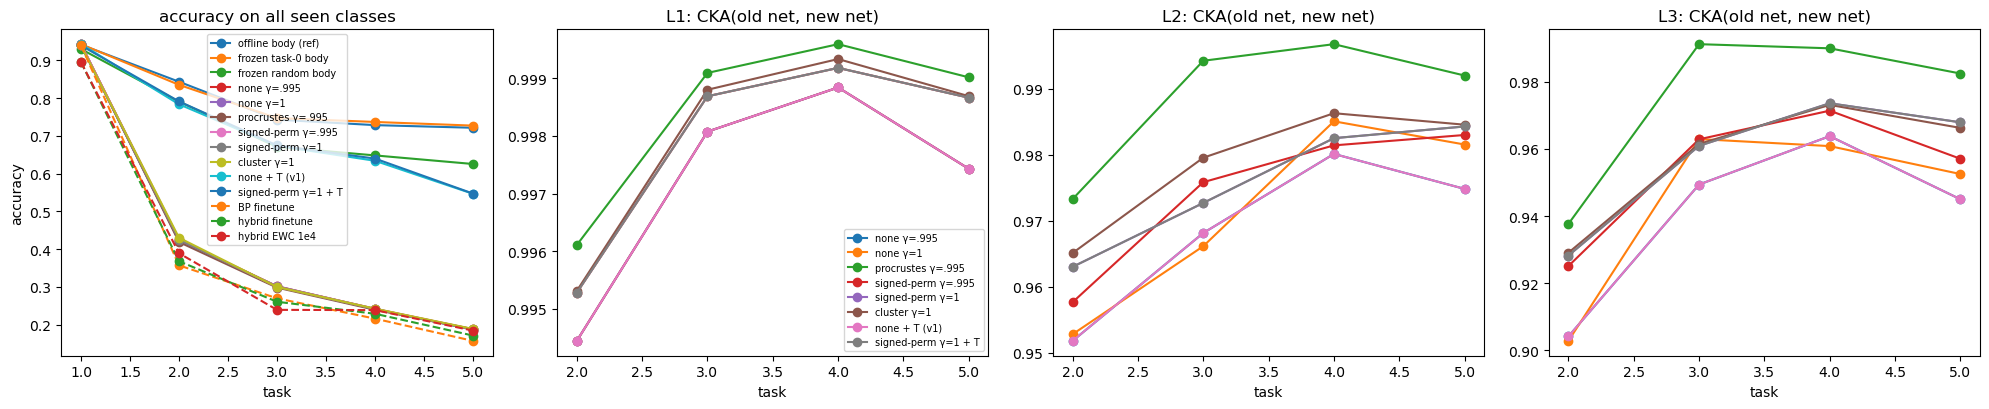

In [11]:
import matplotlib.pyplot as plt

if RESULTS:
    print(f'{"method":24s} {"final all":>9s} {"final t0":>9s} {"avg inc":>8s}')
    for name, h in RESULTS.items():
        print(f'{name:24s} {h[-1]["all"]:9.3f} {h[-1]["task0"]:9.3f} {np.mean([r["all"] for r in h]):8.3f}')

    fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
    steps = range(1, len(TASKS) + 1)
    for name, h in RESULTS.items():
        ls = '--' if ('BP' in name or 'hybrid' in name) else '-'
        ax[0].plot(steps, [r['all'] for r in h], marker='o', ls=ls, label=name)
        if 'cka' in h[-1]:
            for j in range(3):
                ax[j + 1].plot(list(steps)[1:], [r['cka'][j] for r in h[1:]], marker='o', label=name)
    ax[0].set(title='accuracy on all seen classes', xlabel='task', ylabel='accuracy')
    for j in range(3):
        ax[j + 1].set(title=f'L{j + 1}: CKA(old net, new net)', xlabel='task')
    ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
    fig.tight_layout(); fig.savefig('ci_v2.png', dpi=120)
    plt.show()